# GFZ-Verteilung Österreich – reproduzierbare Bundeslandhochrechnung

2021er Bestandsmodell. **Wien → Wien; Salzburg → alle anderen Bundesländer.** Ausnahmen werden nur bei `fallback="vienna"` ausdrücklich ausgewiesen. Berechnungslogik in `gfz_hydrator.py` und nicht in Notebook-Zellen duplizieren.


In [14]:
from pathlib import Path
from argparse import Namespace
from gfz_hydrator import read_samples, read_statistics, run

DATA = Path("data")
BUILDINGS = DATA / "rohdaten_python.xlsx"
STATISTICS = DATA / "GFZ_Analyse_AT.xlsx"
OUT = Path("outputs/recalculated")
FALLBACK = "vienna"   # Alternative "error" -> zeigt nicht abgedeckte Kombinationen


## 1. Datenprüfung

**GFZ** und **BGF** stammen gebäudescharf aus Wien/Salzburg; Statistikdaten nach Bundesland, Geschossklasse und Hauptnutzung. Zur Vollständigkeit der Klassenzuordnungen siehe `reference_coverage.csv`.


In [15]:
buildings, building_meta = read_samples(BUILDINGS, max_gfz=20.0)
targets, target_meta = read_statistics(STATISTICS, ngf_per_bgf=0.8)
display(buildings.groupby(["Bundesland", "GK"])["BGF"].agg(["count", "sum"]).round(1))
print(building_meta)
print(target_meta)


c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


count         sum
Bundesland GK                     
Salzburg   1      1898    750374.0
           11+       1      3786.5
           2     27724   9170769.8
           3     30175  13802602.8
           4      6519   6804714.2
           5      2279   3798706.8
           6-10   1770   4389032.9
Wien       1     16218   1706310.0
           11+     441   7504512.0
           2     18879   4885885.0
           3     16953   7532313.0
           4      6677   6519489.0
           5      5267   8194132.0
           6-10  23549  72472928.0

{'sample_rows_original': 170163, 'sample_rows_usable': 158350, 'excluded_other_uses': 11811, 'excluded_invalid_numeric': 0, 'excluded_gfz_above_max': 2, 'excluded_unexpected_region': 0, 'excluded_bgf_m2_total': 3843501.6, 'sample_gfz_max': 36.52210884353742}
{'statistics_ngf_total_m2': 847147914.0, 'statistics_bgf_total_m2': 1058934892.5, 'national_minus_provinces_ngf_m2': 0.0, 'ngf_per_bgf_assumption': 0.8, 'excluded_legacy_aggregate_rows': {'AT ohne Wien und Salzburg': 7, 'Alles': 1}}


## 2. Hochrechnung inklusive Flächenbilanz

`--fallback vienna` verwendet bei weniger als fünf Gebäuden eine **gekennzeichnete** Ersatzreferenz. Diese Ersatzregel wurde am 21.10.2026 vom Auftraggeber freigegeben. Die Bestandsrechnung ist noch keine Kalibrierung des PEQ-Standards für 2040.


In [16]:
args = Namespace(buildings=BUILDINGS, statistics=STATISTICS, out=OUT, ngf_per_bgf=0.8,
                 gfz_step=0.1, gfz_max=20.0, min_samples=5, method="kde", fallback=FALLBACK)
report = run(args)
for k in ("statistics_bgf_total_m2", "allocated_bgf_m2", "total_allocation_residual_m2", "n_fallback_cells", "fallback_share_of_total_bgf"):
    print(f"{k}: {report[k]}")


c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\schneids\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


statistics_bgf_total_m2: 1058934892.5
allocated_bgf_m2: 1058934892.4999999
total_allocation_residual_m2: -1.1920928955078125e-07
n_fallback_cells: 91
fallback_share_of_total_bgf: 0.016960820846688644


## 3. Validierung und Figuren

Die Hauptdaten liegen in `gfz_distribution_by_province_use_storeys.csv`. Für die Berichtstexte primär `allocation_audit.csv` und `validation.json` prüfen.


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,Bundesland,GK,GWR_Nutzung,status,reference_region,reference_gk,BGF_target_m2
24,Oberösterreich,11+,Hotels o.Ä.,fallback-vienna-exact,Wien,11+,36171.25
43,Tirol,11+,Hotels o.Ä.,fallback-vienna-exact,Wien,11+,123687.50
50,Vorarlberg,11+,Hotels o.Ä.,fallback-vienna-exact,Wien,11+,6262.50
70,Kärnten,11+,Büronutzung,fallback-vienna-exact,Wien,11+,47692.50
77,Niederösterreich,11+,Büronutzung,fallback-vienna-exact,Wien,11+,79090.00
...,...,...,...,...,...,...,...
438,Steiermark,11+,Mehrfamilienhaus,fallback-vienna-exact,Wien,11+,974400.00
445,Tirol,11+,Mehrfamilienhaus,fallback-vienna-exact,Wien,11+,678133.75
452,Vorarlberg,11+,Mehrfamilienhaus,fallback-vienna-exact,Wien,11+,161016.25
478,Niederösterreich,11+,Ein- und Zweifamilienhäuser,fallback-vienna-exact,Wien,11+,853.75


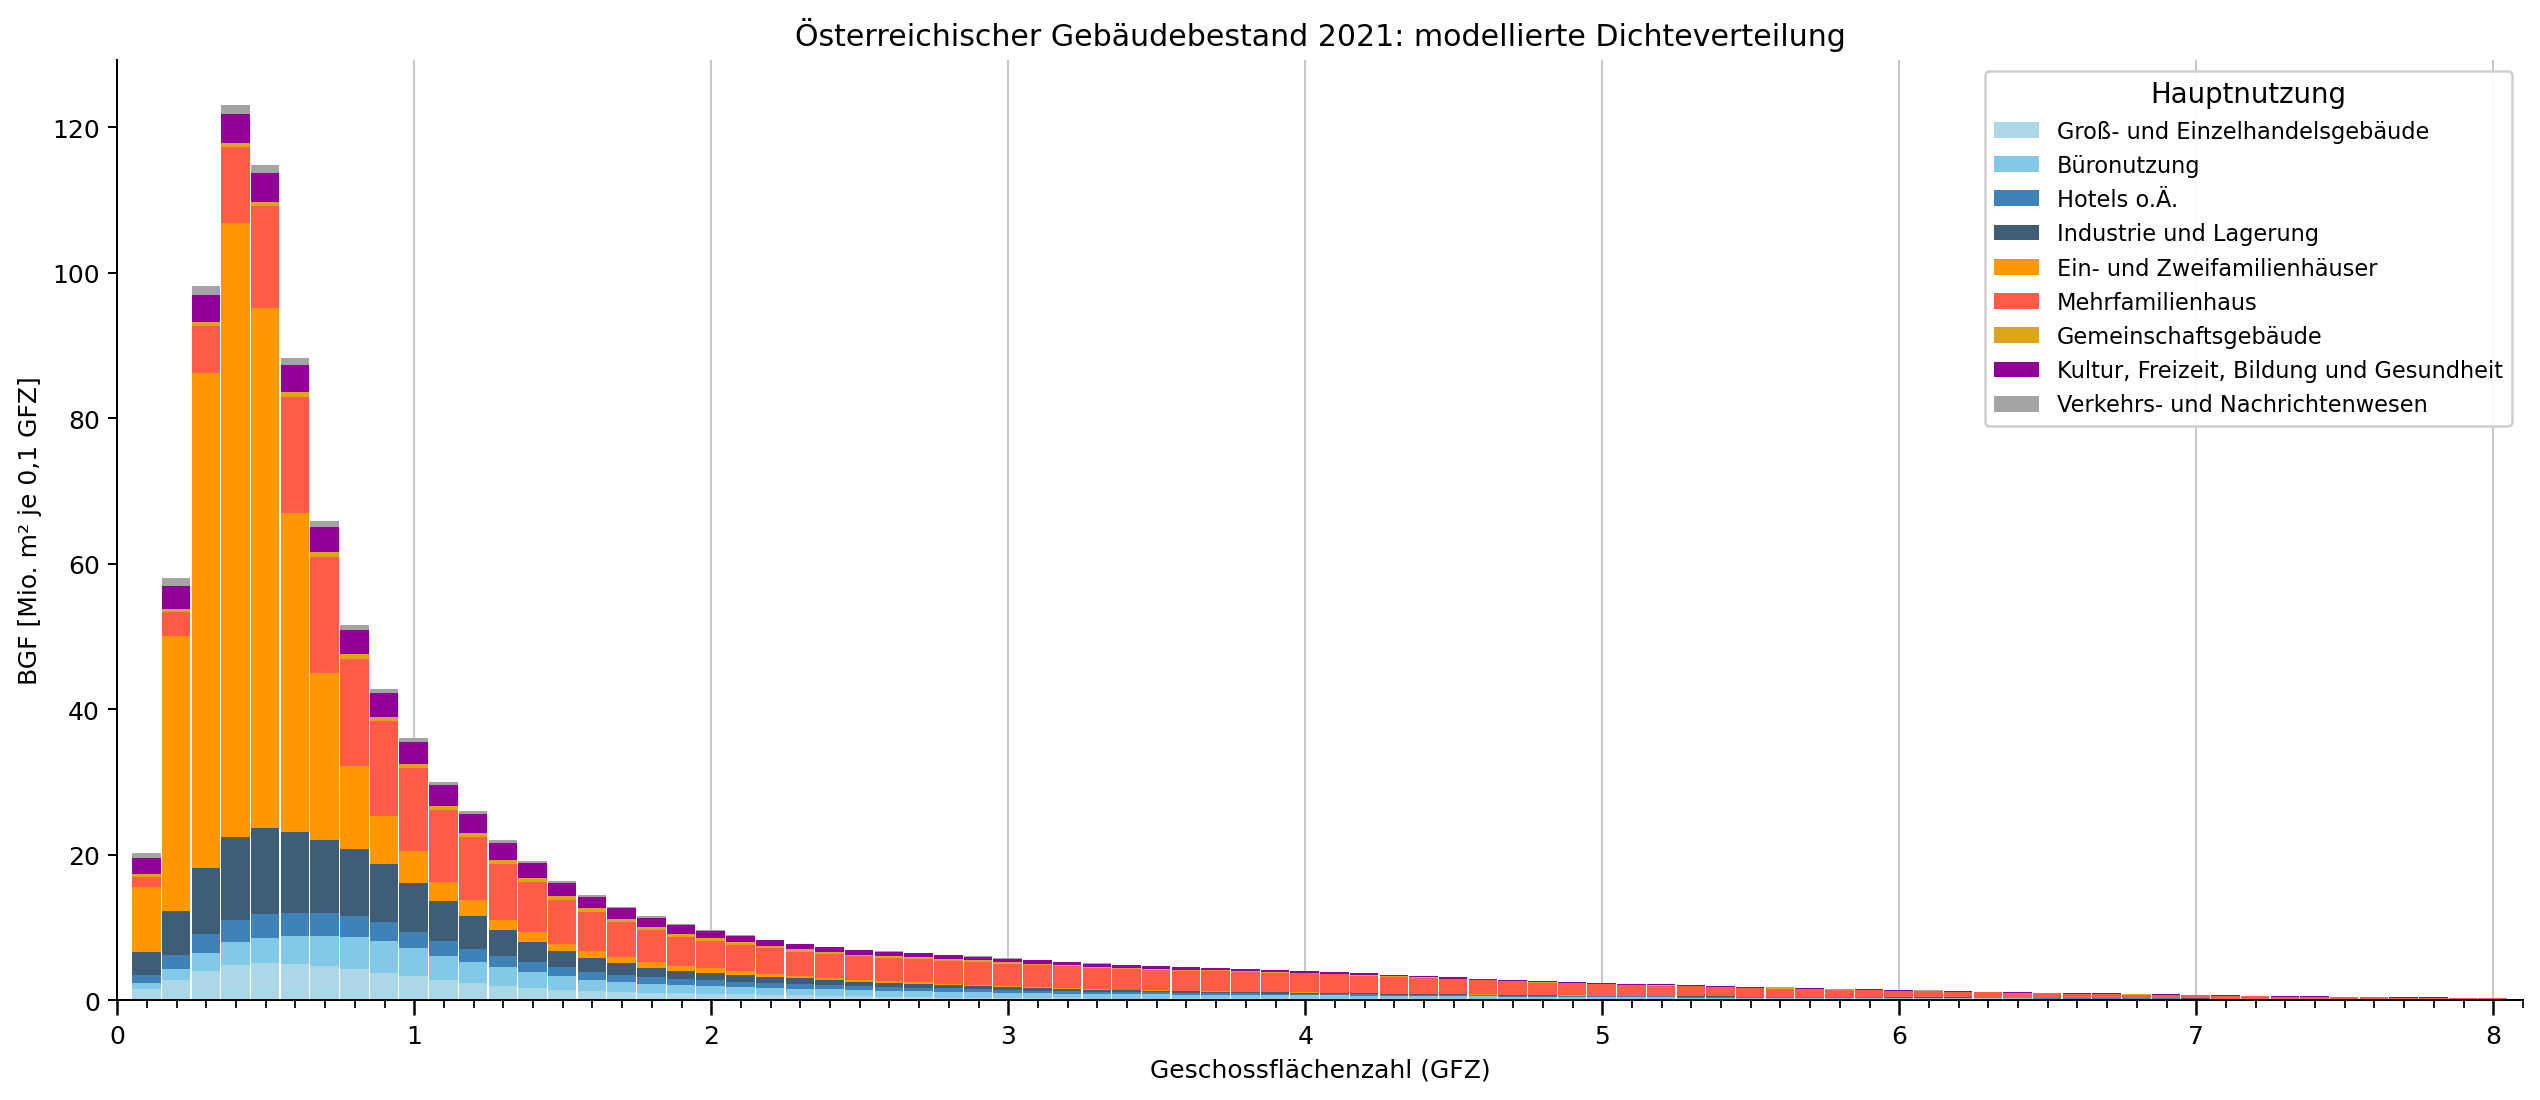

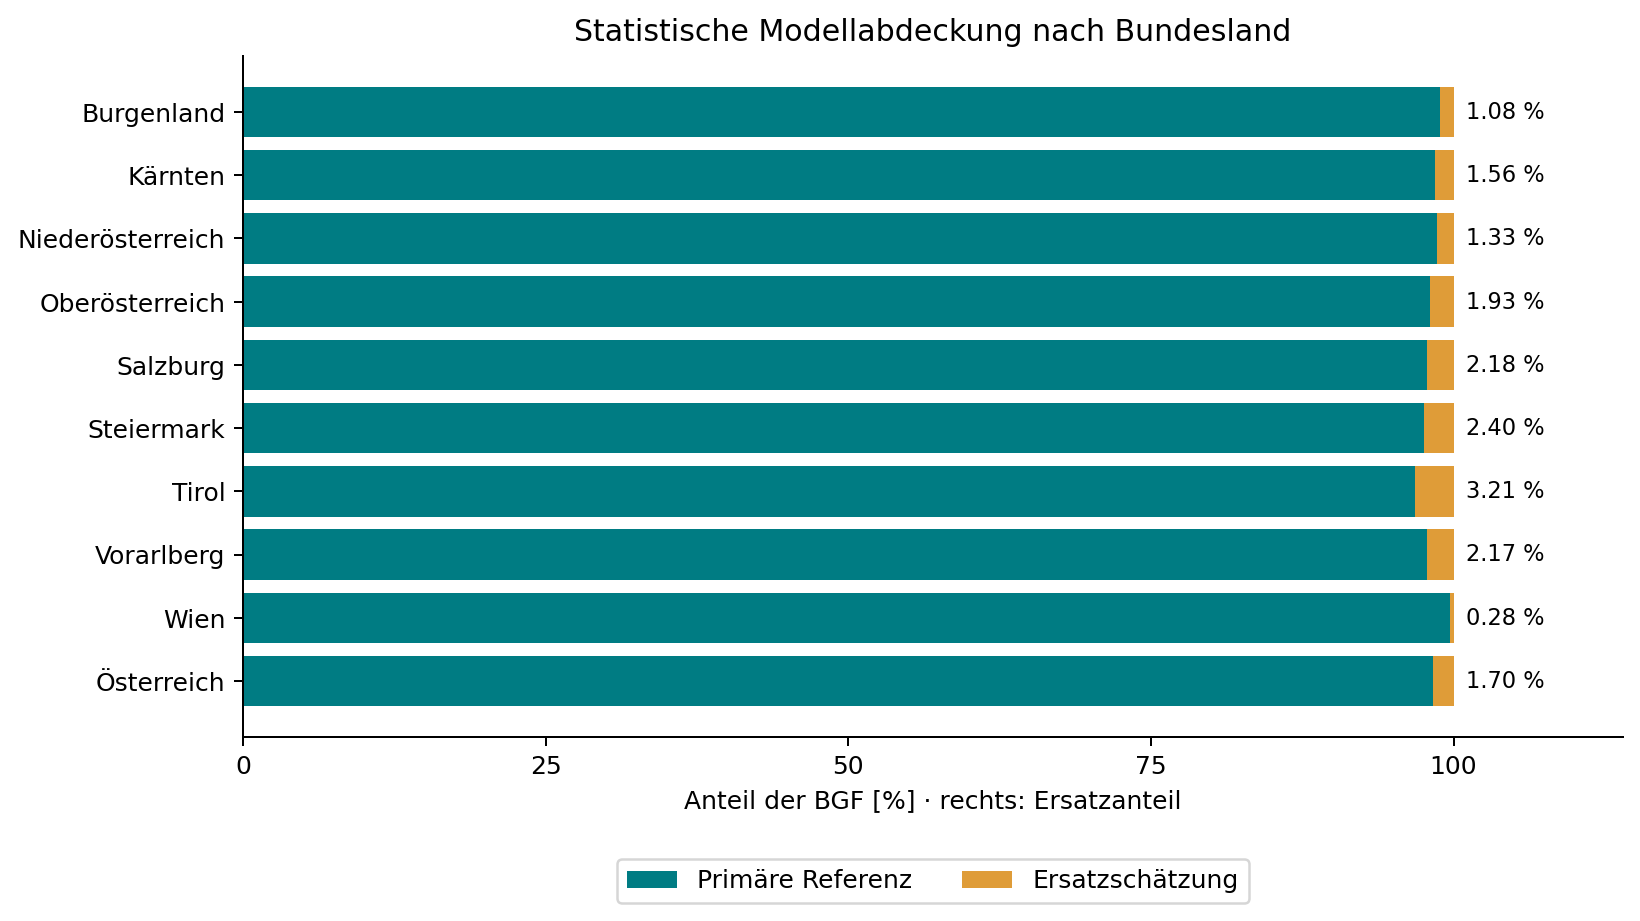

In [19]:
%load_ext autoreload
%autoreload 2

from plot_gfz import make_figures

import pandas as pd
audit = pd.read_csv(OUT / "allocation_audit.csv")
display(audit.loc[audit.status != "reference-exact", ["Bundesland", "GK", "GWR_Nutzung", "status", "reference_region", "reference_gk", "BGF_target_m2"]])
make_figures(OUT, OUT)
from IPython.display import Image, display
display(Image(filename=str(OUT / "gfz_oesterreich_nutzung.png")))
display(Image(filename=str(OUT / "fallback_bundeslaender.png")))


## 4. Methodische Einschränkungen

Phase 2 wird nur dokumentiert, ohne Sensitivitäts- oder Nachbearbeitungsschleife. Offene Punkte siehe `METHODENSTAND.md`. `method="histogram"` bleibt für eine spätere Untersuchung verfügbar.


In [18]:
# Optionale zweite Rechnung:
# args.method = "histogram"
# args.out = Path("outputs_hist")
# report_hist = run(args)
